# 11 · Multi-Scale Conv1D

**The question:** Our network's convolution looks at **3 neighbouring features** at a time. Does it help to look at **3, 5 and 7** neighbours at once
(a *multi-scale* convolution)?

| | |
|---|---|
| **Input** | Scaled `total_and_byte44` inputs; the network weighting chosen in Notebook 10 |
| **What we do** | Train the same network with a single-scale and a multi-scale convolution, 3 seeds each, and compare |
| **Output** | A decision: keep multi-scale or not. Notebook 12 builds on the winner |

**Decision rule (fixed before training, the same in Notebooks 11-13):** a new block is kept only if it raises the **3-seed mean macro F1** and is
better in **at least 2 of the 3 seeds**.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import f1_score

from src.notebook_helpers import TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS, sha256, save_table, save_figure, save_json, read_json, setup_style, write_leaderboard
from src.flow_networks import FlowData, BASE_CONFIG, ConvBranch, run_config, paired_comparison, leaderboard_row, show_code, DEVICE
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

WEIGHTING = read_json(MODELS / '10_rare_class_choice.json')['network_weighting']
print(f'network weighting from Notebook 10: {WEIGHTING} | device: {DEVICE}')
data = FlowData('total_and_byte44')

network weighting from Notebook 10: sqrt | device: cuda


## 2. What does "multi-scale" mean?

A convolution with window size 3 combines each feature with its 2 direct neighbours in our topic order. A window of 5 or 7 reaches further.
Here is what each window sees around `sttl` (time-to-live) in branch A:

In [2]:
position = data.branch_a.index('sttl')
for k in (3, 5, 7):
    half = k // 2
    window = data.branch_a[max(0, position - half): position + half + 1]
    print(f'window {k}: {window}')

window 3: ['ackdat', 'sttl', 'dttl']
window 5: ['synack', 'ackdat', 'sttl', 'dttl', 'swin']
window 7: ['tcprtt', 'synack', 'ackdat', 'sttl', 'dttl', 'swin', 'dwin']


A larger window can combine, for example, TTL with TCP timing *and* window sizes in one step. The multi-scale block runs all three windows in
parallel and mixes the results:

In [3]:
show_code(ConvBranch)

```python
class ConvBranch(nn.Module):
    """Two Conv1D layers over an ordered feature sequence. scales=(3,) is the Notebook 08 branch;
    scales=(3, 5, 7) runs parallel convolutions with several window sizes and joins their channels (multi-scale)."""

    def __init__(self, scales=(3,), channels=64):
        super().__init__()
        per_scale = channels // len(scales)
        self.paths = nn.ModuleList([nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=k, padding=k // 2), nn.ReLU(),
            nn.Conv1d(32, per_scale, kernel_size=k, padding=k // 2), nn.ReLU()) for k in scales])
        self.mix = nn.Conv1d(per_scale * len(scales), channels, kernel_size=1)   # combine the scales into `channels`

    def forward(self, x):                                   # x: (batch, length)
        x = x[:, None, :]
        return self.mix(torch.cat([path(x) for path in self.paths], dim=1)).transpose(1, 2)   # (batch, length, channels)

```

To keep the comparison fair, the multi-scale branch has about the same total width (64 channels) as the single-scale one, so it does not simply
win by being bigger. The parameter counts are shown in the results.

## 3. Train both versions (3 seeds each)

In [4]:
SINGLE = dict(BASE_CONFIG, weighting=WEIGHTING, scales=[3])
MULTI = dict(BASE_CONFIG, weighting=WEIGHTING, scales=[3, 5, 7])
single_runs, single_proba, _, single_hist = run_config(data, SINGLE, label='single-scale (3)')
multi_runs, multi_proba, _, multi_hist = run_config(data, MULTI, label='multi-scale (3, 5, 7)')

single-scale (3) seed 42: model_selection macro F1 0.6043 | stopping macro F1 0.6018
single-scale (3) seed 43: model_selection macro F1 0.5787 | stopping macro F1 0.5854


single-scale (3) seed 44: model_selection macro F1 0.5794 | stopping macro F1 0.5913
multi-scale (3, 5, 7) seed 42: model_selection macro F1 0.5928 | stopping macro F1 0.5932


multi-scale (3, 5, 7) seed 43: model_selection macro F1 0.5889 | stopping macro F1 0.5984
multi-scale (3, 5, 7) seed 44: model_selection macro F1 0.5975 | stopping macro F1 0.6009


## 4. Results

,experiment,seed,macro F1,accuracy,false-positive rate,Worms correct (of 13),epochs,train minutes,parameters
0,single-scale (3),42,0.6043,0.7925,0.1704,8,66,2.3311,60234
1,single-scale (3),43,0.5787,0.7941,0.1963,7,39,1.3874,60234
2,single-scale (3),44,0.5794,0.7868,0.1891,7,32,1.1155,60234
3,"multi-scale (3, 5, 7)",42,0.5928,0.7885,0.1905,7,40,1.7190,68872
4,"multi-scale (3, 5, 7)",43,0.5889,0.7900,0.1880,6,35,1.5922,68872
5,"multi-scale (3, 5, 7)",44,0.5975,0.7898,0.1941,7,39,1.6597,68872


,mean,std,min,max
experiment,,,,
single-scale (3),0.5875,0.0146,0.5787,0.6043
"multi-scale (3, 5, 7)",0.5931,0.0043,0.5889,0.5975


,comparison,seed,difference,95% low,95% high,verdict
0,multi-scale vs single-scale,42,-0.0115,-0.0227,-0.0022,second clearly better
1,multi-scale vs single-scale,43,0.0102,-0.0005,0.0206,could be chance
2,multi-scale vs single-scale,44,0.0181,0.0098,0.0271,first clearly better


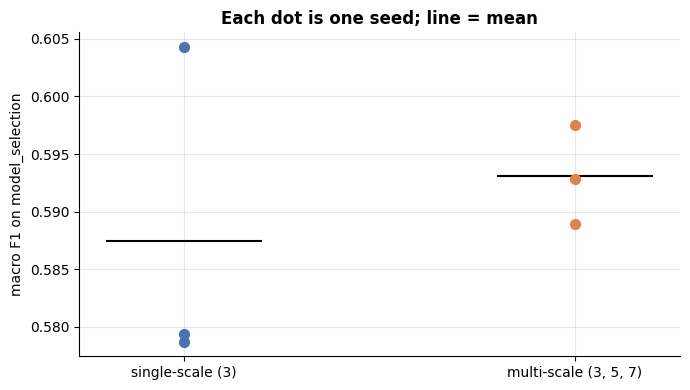

In [5]:
runs = pd.concat([single_runs, multi_runs], ignore_index=True)
save_table(runs, '11_runs')
display(runs[['experiment', 'seed', 'macro F1', 'accuracy', 'false-positive rate', 'Worms correct (of 13)', 'epochs', 'train minutes', 'parameters']])
summary = runs.groupby('experiment', sort=False)['macro F1'].agg(['mean', 'std', 'min', 'max'])
display(summary)

y_eval = data.y['model_selection'].numpy()
comparison, overall = paired_comparison(y_eval, multi_proba, single_proba, 'multi-scale vs single-scale')
save_table(comparison, '11_comparison')
display(comparison)

fig, ax = plt.subplots(figsize=(7, 4))
for i, (name, r) in enumerate([('single-scale (3)', single_runs), ('multi-scale (3, 5, 7)', multi_runs)]):
    ax.scatter([i] * len(r), r['macro F1'], s=50, color=['#4C72B0', '#DD8452'][i], zorder=3)
    ax.hlines(r['macro F1'].mean(), i - 0.2, i + 0.2, color='black')
ax.set_xticks([0, 1], ['single-scale (3)', 'multi-scale (3, 5, 7)']); ax.set(ylabel='macro F1 on model_selection', title='Each dot is one seed; line = mean')
plt.tight_layout(); save_figure(fig, '11_scales'); plt.show()

## 5. Class by class

In [6]:
per_class = pd.DataFrame({
    'single-scale F1 (mean of seeds)': np.mean([f1_score(y_eval, p.argmax(1), average=None, labels=range(10), zero_division=0) for p in single_proba.values()], axis=0),
    'multi-scale F1 (mean of seeds)': np.mean([f1_score(y_eval, p.argmax(1), average=None, labels=range(10), zero_division=0) for p in multi_proba.values()], axis=0),
}, index=CLASSES)
per_class['change'] = per_class.iloc[:, 1] - per_class.iloc[:, 0]
save_table(per_class, '11_per_class', index=True)
display(per_class.round(3))

,single-scale F1 (mean of seeds),multi-scale F1 (mean of seeds),change
Analysis,0.2530,0.2750,0.0210
Backdoor,0.2160,0.2420,0.0270
DoS,0.4510,0.4710,0.0200
Exploits,0.6780,0.6690,-0.0080
Fuzzers,0.7070,0.7130,0.0050
Generic,0.9880,0.9880,-0.0000
Normal,0.8930,0.8920,-0.0020
Reconnaissance,0.8240,0.8250,0.0010
Shellcode,0.5680,0.5780,0.0100
Worms,0.2960,0.2780,-0.0180


**What we see:**

- **Multi-scale is slightly better on average** (0.593 vs 0.588) and better for 2 of the 3 seeds, but the seed-by-seed tests **disagree**:
  clearly worse for seed 42, chance for seed 43, clearly better for seed 44. The average gain is small and not reliable on its own.
- **Its clearest effect is stability:** the spread between seeds drops from 0.015 to 0.004. The single-scale network has one lucky seed (0.604) and two
  weaker ones; the multi-scale network is consistently near 0.59.
- Per class, multi-scale helps the hard, conflicting classes a little (Analysis +0.02, Backdoor +0.03, DoS +0.02) and costs a little on Worms (-0.02,
  about one row out of 13).
- Both versions have about the same size (60k vs 69k parameters), so the difference is not simply more capacity.

## 6. Decision

In [7]:
wins = int(sum(multi_runs.set_index('seed')['macro F1'] > single_runs.set_index('seed')['macro F1']))
gain = multi_runs['macro F1'].mean() - single_runs['macro F1'].mean()
keep = bool(gain > 0 and wins >= 2)
decision = {'block': 'multi-scale convolution', 'mean gain': round(float(gain), 4), 'seeds where better': f'{wins} of 3',
            'bootstrap verdict over seeds': overall, 'kept': keep, 'scales': [3, 5, 7] if keep else [3]}
save_json(decision, MODELS / '11_decision.json')
display(pd.Series(decision).to_frame('decision'))
write_leaderboard('11', [leaderboard_row(f'FlowNet single-scale ({WEIGHTING})', single_runs),
                         leaderboard_row(f'FlowNet multi-scale ({WEIGHTING})', multi_runs)])
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

,decision
block,multi-scale convolution
mean gain,0.0056
seeds where better,2 of 3
bootstrap verdict over seeds,depends on the seed
kept,True
scales,"[3, 5, 7]"


## Summary

### What we learned

| Question | Answer |
|---|---|
| Does multi-scale convolution help? | **A little, and not reliably:** +0.006 mean macro F1, better in 2 of 3 seeds, bootstrap verdict depends on the seed |
| What does it clearly do? | Makes the network **more stable across seeds** (std 0.015 → 0.004) |
| Decision (by the fixed rule) | **Kept**: scales 3, 5 and 7 |

### What is still uncertain

- Whether the small gain holds on new data; the ablation study (Notebook 15) removes it again under the final design, and Notebook 19 reports test results.

### What comes next

**Notebook 12** tests the second block: cross-attention fusion between flow measurements and context.